# Lab 1 for EC3318/MN3101 Corporate Finance

**Contents**:

1. Starting your notebook
2. Loading stock price data
3. Computing stock returns
4. Visualising stock prices and returns

**Instructions**:

1. Read the notebook
2. Execute code cells as you encounter them
3. If you want help, ask GitHub Copilot to explain a concept or Python syntax. AI is optional; no AI subscription is needed.

## 1. Starting your notebook

In Codespaces, open this notebook and run the first code cell below with its play button (or Shift+Enter). Work through the cells in order.

If you see an import error:

1. Run **Terminal → Run Task → Setup lab environment** again.
2. Use **Select Kernel** at the top right and select **Corporate Finance Labs (.venv)**. If it is not listed, choose **Python Environments → .venv**.
3. Run the cell again.

A notebook combines short code cells, results and explanations. You can edit a cell and run it again to explore what changes. Setup details are in the [optional reference](docs/reference.md).

In [1]:
# Import essential data manipulation package
import pandas as pd
import numpy as np

**Ready to start**

Your environment is pre-configured and ready to use. Focus on your analysis - the technical setup is handled for you!


## 2. Loading stock price data

Now we'll work with real stock price data from our Excel file.


In [2]:
# Load stock price data from Excel file
prices_raw = pd.read_excel(
    io="EC3318 Technical Assessment.xlsx",  # our Excel file
    sheet_name="Sheet1",  # Sheet in Excel file
    skiprows=7,  # Skip first 7 rows in sheet
)

prices_raw

,date,MSFT,NVDA,AMZN,TSLA,PEP,WMT,JNJ,NEE,AAPL,HSBC,CAT,SHEL,BHP,VZ,TM
0,42614,57.60,1.7130,41.8655,13.6019,108.77,24.0398,118.13,30.5800,28.2625,37.61,88.77,50.07,30.9002,51.98,116.06
1,42644,59.92,1.7790,39.4910,13.1819,107.20,23.3398,115.99,32.0000,28.3850,37.63,83.46,49.81,31.2301,48.10,115.66
2,42675,60.26,2.3050,37.5285,12.6265,100.10,23.4764,111.30,28.5575,27.6300,39.54,95.56,51.10,33.4774,49.90,118.53
3,42705,62.14,2.6685,37.4935,14.2459,104.63,23.0398,115.21,29.8650,28.9550,40.18,92.74,54.38,31.9079,53.38,117.20
4,42736,64.65,2.7295,41.1740,16.7952,103.78,22.2464,113.25,30.9300,30.3375,42.60,95.66,54.39,36.8216,49.01,115.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,46143,450.24,211.1400,270.6400,435.7900,144.19,115.7500,225.33,87.0100,312.0600,93.74,875.87,84.12,88.9100,47.81,189.95
117,46174,373.02,200.0900,238.3400,420.6000,135.40,113.2600,253.97,87.7700,289.3600,95.09,1064.90,77.54,83.3100,42.34,168.42
118,46204,464.72,200.7500,271.5800,311.2100,139.56,111.2000,256.35,86.9200,308.9100,106.42,814.81,91.98,84.4900,46.81,188.99
119,46235,507.29,220.7800,259.7700,367.9500,140.34,104.8700,265.85,82.3400,316.8500,103.14,797.47,91.45,93.9200,50.02,196.54


**Why Excel data matters in finance**

Excel remains ubiquitous in financial practice. Investment banks, asset managers, and corporate finance teams routinely receive data in Excel format from Bloomberg, Refinitiv, and other financial data providers.

Learning to programmatically import Excel data is essential because:

- Manual copy-pasting introduces errors and is not reproducible
- Financial models require regular updates with new data
- Regulatory compliance often demands audit trails of data sources
- Large datasets exceed Excel's row limitations (1,048,576 rows)


In [3]:
# Import datetime library for working with dates
from datetime import datetime, timedelta

# Convert Excel numeric date to a normal date
prices_raw["date"] = pd.to_datetime(
    prices_raw["date"],  # date column
    unit="D",  # in days
    origin="1899-12-30",  # the date that a number of zero represents
)

prices_raw

,date,MSFT,NVDA,AMZN,TSLA,PEP,WMT,JNJ,NEE,AAPL,HSBC,CAT,SHEL,BHP,VZ,TM
0,2016-09-01,57.60,1.7130,41.8655,13.6019,108.77,24.0398,118.13,30.5800,28.2625,37.61,88.77,50.07,30.9002,51.98,116.06
1,2016-10-01,59.92,1.7790,39.4910,13.1819,107.20,23.3398,115.99,32.0000,28.3850,37.63,83.46,49.81,31.2301,48.10,115.66
2,2016-11-01,60.26,2.3050,37.5285,12.6265,100.10,23.4764,111.30,28.5575,27.6300,39.54,95.56,51.10,33.4774,49.90,118.53
3,2016-12-01,62.14,2.6685,37.4935,14.2459,104.63,23.0398,115.21,29.8650,28.9550,40.18,92.74,54.38,31.9079,53.38,117.20
4,2017-01-01,64.65,2.7295,41.1740,16.7952,103.78,22.2464,113.25,30.9300,30.3375,42.60,95.66,54.39,36.8216,49.01,115.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,2026-05-01,450.24,211.1400,270.6400,435.7900,144.19,115.7500,225.33,87.0100,312.0600,93.74,875.87,84.12,88.9100,47.81,189.95
117,2026-06-01,373.02,200.0900,238.3400,420.6000,135.40,113.2600,253.97,87.7700,289.3600,95.09,1064.90,77.54,83.3100,42.34,168.42
118,2026-07-01,464.72,200.7500,271.5800,311.2100,139.56,111.2000,256.35,86.9200,308.9100,106.42,814.81,91.98,84.4900,46.81,188.99
119,2026-08-01,507.29,220.7800,259.7700,367.9500,140.34,104.8700,265.85,82.3400,316.8500,103.14,797.47,91.45,93.9200,50.02,196.54


In [4]:
# Shape of data
prices_raw.shape

(121, 16)

In [5]:
# Columns
prices_raw.columns.tolist()

['date',
 'MSFT',
 'NVDA',
 'AMZN',
 'TSLA',
 'PEP',
 'WMT',
 'JNJ',
 'NEE',
 'AAPL',
 'HSBC',
 'CAT',
 'SHEL',
 'BHP',
 'VZ',
 'TM']

In [6]:
# Data types
prices_raw.dtypes

date    datetime64[ns]
MSFT           float64
NVDA           float64
AMZN           float64
TSLA           float64
PEP            float64
WMT            float64
JNJ            float64
NEE            float64
AAPL           float64
HSBC           float64
CAT            float64
SHEL           float64
BHP            float64
VZ             float64
TM             float64
dtype: object

In [7]:
# Date range
[
    prices_raw["date"].min(),  # earliest date in data
    prices_raw["date"].max(),  # latest date
]

[Timestamp('2016-09-01 00:00:00'), Timestamp('2026-09-01 00:00:00')]

In [8]:
# Check for missing values
prices_raw.isnull().sum()

date    0
MSFT    0
NVDA    0
AMZN    0
TSLA    0
PEP     0
WMT     0
JNJ     0
NEE     0
AAPL    0
HSBC    0
CAT     0
SHEL    0
BHP     0
VZ      0
TM      0
dtype: int64

**Data quality checks: Foundation of financial analysis**

Before analyzing any financial data, rigorous quality checks are mandatory. Missing values, incorrect dates, and outliers can lead to:

- **Incorrect valuations** in DCF models
- **Flawed risk assessments** for portfolio management
- **Regulatory violations** in financial reporting
- **Trading losses** from bad signals

Professional practice requires documenting these checks for audit purposes and regulatory compliance (e.g., Basel III, Solvency II, IFRS 9).


In [9]:
# Transform from wide format to tidy (long) format

# Melt the dataframe to convert from wide to long format
prices_tidy = pd.melt(
    prices_raw,  # our data
    id_vars=["date"],  # column that identifies rows in wide data
    var_name="symbol",  # new column for current variable names
    value_name="adj_close",  # new column for respective table values
)
prices_tidy

,date,symbol,adj_close
0,2016-09-01,MSFT,57.60
1,2016-10-01,MSFT,59.92
2,2016-11-01,MSFT,60.26
3,2016-12-01,MSFT,62.14
4,2017-01-01,MSFT,64.65
...,...,...,...
1810,2026-05-01,TM,189.95
1811,2026-06-01,TM,168.42
1812,2026-07-01,TM,188.99
1813,2026-08-01,TM,196.54


In [10]:
# Sort by symbol and date for better organization
prices_tidy = (
    prices_tidy.get(["symbol", "date", "adj_close"])  # arrange columns differently
    .sort_values(["symbol", "date"])  # sort rows by symbol and date
    .reset_index(drop=True)  # maintain clean row identifiers
)

prices_tidy

,symbol,date,adj_close
0,AAPL,2016-09-01,28.2625
1,AAPL,2016-10-01,28.3850
2,AAPL,2016-11-01,27.6300
3,AAPL,2016-12-01,28.9550
4,AAPL,2017-01-01,30.3375
...,...,...,...
1810,WMT,2026-05-01,115.7500
1811,WMT,2026-06-01,113.2600
1812,WMT,2026-07-01,111.2000
1813,WMT,2026-08-01,104.8700


**Tidy data: The foundation for scalable financial analysis**

Converting from "wide" to "long" format may seem technical, but it's crucial for financial modeling:

- **Portfolio analysis**: Compare hundreds of securities simultaneously
- **Risk management**: Calculate correlations across multiple assets
- **Performance attribution**: Analyze returns by sector, geography, or style
- **Regulatory reporting**: Format data for XBRL and other regulatory standards

This structure enables vectorized operations essential for high-frequency analysis and real-time risk monitoring.


## 3. Computing stock returns


**Stock returns: Comparing investments**

Simple returns measure the proportional change in value: $r_t=(P_t-P_{t-1})/P_{t-1}$. They let us compare stocks with different price levels. Returns may have more stable properties than prices, but their means and volatility can still change over time.

Simple returns **compound across time**; they are not additive. A +10% month followed by a −10% month gives $(1.10)(0.90)-1=-1\%$, not zero. For several periods, the cumulative return is $\prod_t(1+r_t)-1$.

For a portfolio over one period, returns are a weighted average of its assets' returns, using weights at the start of that period.

In [11]:
# Calculate returns for each stock

returns = (
    prices_tidy.sort_values(["symbol", "date"])  # verify sorted rows
    .assign(
        ret=prices_tidy.groupby("symbol")["adj_close"].pct_change(fill_method=None)
    )  # calculate returns
    .reset_index(drop=True)  # clean row identifiers
)

# look at first five rows per stock
returns.groupby("symbol").head()

,symbol,date,adj_close,ret
0,AAPL,2016-09-01,28.2625,NaN
1,AAPL,2016-10-01,28.3850,0.004334
2,AAPL,2016-11-01,27.6300,-0.026599
3,AAPL,2016-12-01,28.9550,0.047955
4,AAPL,2017-01-01,30.3375,0.047747
...,...,...,...,...
1694,WMT,2016-09-01,24.0398,NaN
1695,WMT,2016-10-01,23.3398,-0.029118
1696,WMT,2016-11-01,23.4764,0.005853
1697,WMT,2016-12-01,23.0398,-0.018597


In [12]:
# Drop unavailable returns, including the first row for each stock
returns = returns.dropna(subset=["ret"])

# look at first five rows per stock
returns.groupby("symbol").head()

,symbol,date,adj_close,ret
1,AAPL,2016-10-01,28.3850,0.004334
2,AAPL,2016-11-01,27.6300,-0.026599
3,AAPL,2016-12-01,28.9550,0.047955
4,AAPL,2017-01-01,30.3375,0.047747
5,AAPL,2017-02-01,34.2475,0.128883
...,...,...,...,...
1695,WMT,2016-10-01,23.3398,-0.029118
1696,WMT,2016-11-01,23.4764,0.005853
1697,WMT,2016-12-01,23.0398,-0.018597
1698,WMT,2017-01-01,22.2464,-0.034436


**Missing returns**

The first price for each stock has no preceding price, so its return is missing. A missing price also prevents calculating the adjacent one-period returns. We use `fill_method=None` to avoid inventing prices by carrying the previous price forward, then drop unavailable returns. Check missing values before doing this: dropping observations can change the sample.

## 4. Visualising stock prices and returns


**Visualization in financial analysis: Beyond pretty charts**

Effective visualization is critical for:

- **Risk communication** to boards and regulators
- **Pattern recognition** in market anomalies and trading strategies
- **Performance reporting** to institutional investors
- **Stress testing** under different market scenarios

The plots we'll create mirror those used in professional investment management: price charts for performance tracking and return histograms for risk assessment.


In [13]:
# Focus on Amazon stock
amazon_data = returns.query("symbol == 'AMZN'")  # filter for AMZN symbol
amazon_data

,symbol,date,adj_close,ret
122,AMZN,2016-10-01,39.4910,-0.056717
123,AMZN,2016-11-01,37.5285,-0.049695
124,AMZN,2016-12-01,37.4935,-0.000933
125,AMZN,2017-01-01,41.1740,0.098164
126,AMZN,2017-02-01,42.2520,0.026182
...,...,...,...,...
237,AMZN,2026-05-01,270.6400,0.021052
238,AMZN,2026-06-01,238.3400,-0.119347
239,AMZN,2026-07-01,271.5800,0.139465
240,AMZN,2026-08-01,259.7700,-0.043486


In [14]:
# Summary statistics
pd.DataFrame(amazon_data["ret"].describe()).round(3).T

,count,mean,std,min,25%,50%,75%,max
ret,120.0,0.019,0.09,-0.238,-0.042,0.021,0.068,0.273


In [15]:
# Yearly summary statistics
(amazon_data["ret"].groupby(amazon_data["date"].dt.year).describe().round(3))

,count,mean,std,min,25%,50%,75%,max
date,,,,,,,,
2016,3.0,-0.036,0.030,-0.057,-0.053,-0.050,-0.025,-0.001
2017,12.0,0.039,0.052,-0.027,-0.006,0.035,0.067,0.150
2018,12.0,0.027,0.113,-0.202,-0.014,0.043,0.064,0.241
2019,12.0,0.019,0.066,-0.079,-0.029,0.019,0.071,0.144
2020,12.0,0.053,0.100,-0.088,-0.019,0.039,0.100,0.269
2021,12.0,0.003,0.057,-0.070,-0.039,-0.008,0.041,0.121
2022,12.0,-0.048,0.126,-0.238,-0.111,-0.077,-0.018,0.271
2023,12.0,0.054,0.087,-0.086,0.024,0.044,0.097,0.228
2024,12.0,0.033,0.059,-0.045,-0.007,0.021,0.065,0.139


**Summary statistics: The language of risk and return**

These statistics form the foundation of modern portfolio theory:

- **Mean**: Expected return (μ) - central to CAPM and asset pricing
- **Standard deviation**: Volatility (σ) - the classic risk measure
- **Min/Max**: Extreme values indicating tail risk
- **Count**: Sample size affecting statistical significance

Notice how these vary by year - this time-varying risk is why financial models use rolling windows and GARCH specifications.


In [16]:
# Import plotnine for producing graphs
# See https://plotnine.org
from plotnine import *

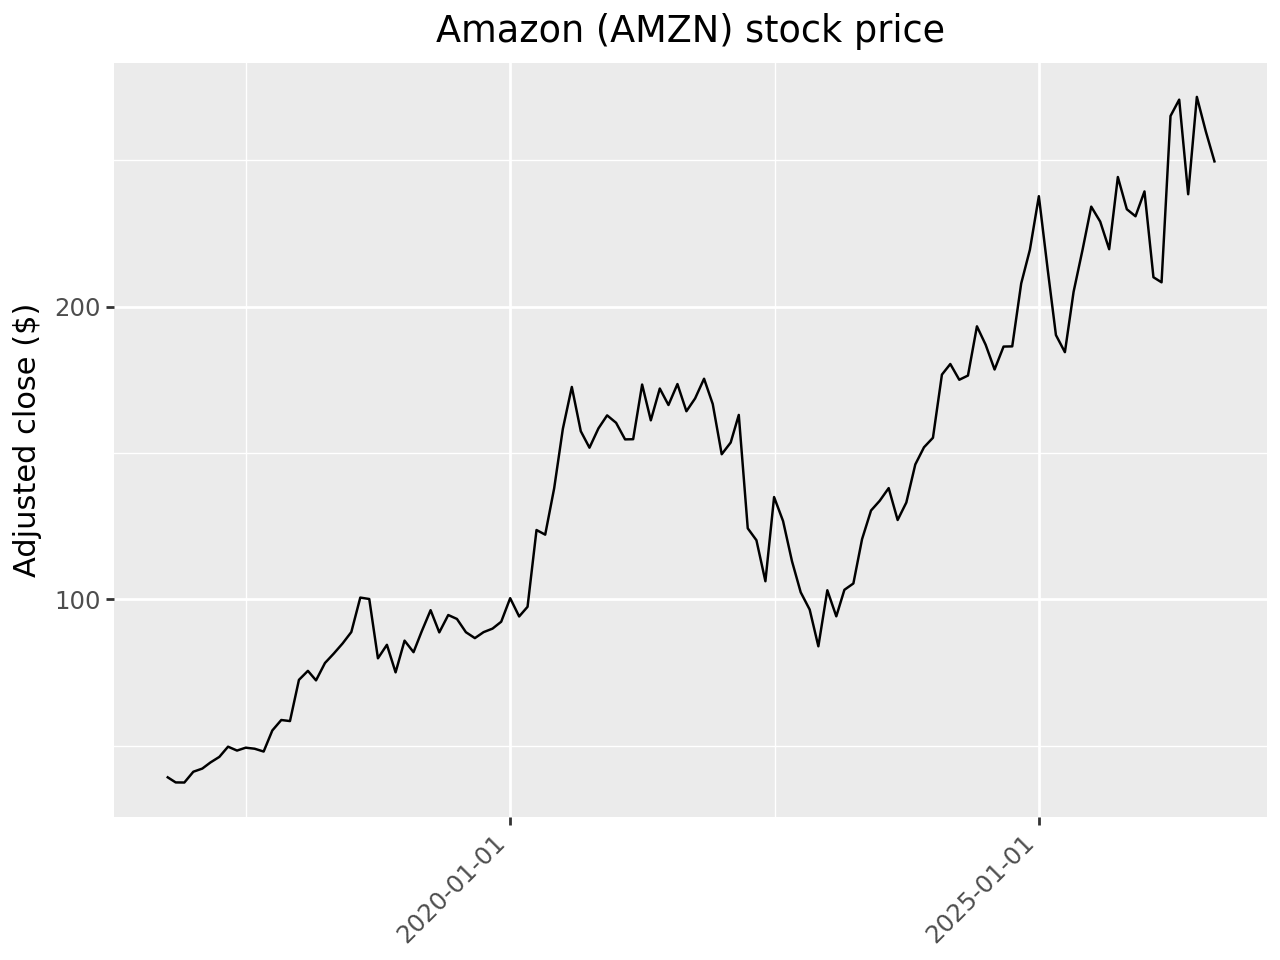

In [17]:
# Plot Amazon stock price
amazon_prices_figure = (
    ggplot(amazon_data, aes(x="date", y="adj_close"))
    + geom_line()
    + labs(x="", y="Adjusted close ($)", title="Amazon (AMZN) stock price")
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)
amazon_prices_figure

In [ ]:
# package for percentage scales
from mizani.formatters import percent_format

# Historical 5th percentile of monthly returns
quantile_05 = amazon_data["ret"].quantile(0.05)
var_95 = -quantile_05  # 95% monthly VaR as a loss fraction

# plot Amazon stock returns histogram with 95% VaR
amazon_returns_figure = (
    ggplot(amazon_data, aes(x="ret"))
    + geom_histogram(bins=100)
    + geom_vline(aes(xintercept=quantile_05), linetype="dashed")
    + labs(x="Monthly return", y="Number of months",
           title="Distribution of monthly Amazon stock returns",
           subtitle="Dashed line: historical 5th percentile of returns")
    + scale_x_continuous(labels=percent_format())
)
amazon_returns_figure

**Value-at-Risk (VaR): A historical loss threshold**

The dashed line is the **5th percentile of monthly returns**. The **95% monthly historical VaR**, expressed as a loss fraction, is the negative of this return quantile (`var_95`). For example, a −12% return quantile means a 12% VaR: about 5% of sample months have losses exceeding that threshold, subject to quantile interpolation.

This describes the historical sample, not a guaranteed future probability. VaR does not tell us how large losses beyond the threshold can be; Expected Shortfall summarises those tail losses.

In [ ]:
# Summary statistics for each stock through groupby-aggregation
summary_stats = (
    returns.groupby("symbol")["ret"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)
summary_stats

In [ ]:
# Annualized statistics
annualized_stats = (
    returns.groupby("symbol")["ret"]  # group by symbol and focus on returns
    .agg(["mean", "std"])  # get means and standard deviations
    .assign(
        ann_mean=lambda x: x["mean"] * 12,  # annualise mean return
        ann_vol=lambda x: x["std"] * np.sqrt(12),  # annualise volatility
    )
    .get(["ann_mean", "ann_vol"])
    .round(3)
)
annualized_stats

**Annualisation: A reporting convention**

We report the **arithmetic annualised mean** as $12\bar r_{\text{monthly}}$ and annualised volatility as $\sqrt{12}s_{\text{monthly}}$. These are the conventions used in Lab 2's mean–variance analysis.

The mean is a scaled monthly estimate, **not a compounded annual return**. Realised returns over 12 months compound as $\prod_{t=1}^{12}(1+r_t)-1$. Under independent identically distributed monthly returns, the expected compounded annual return is $(1+E[r])^{12}-1$.

Square-root-of-time volatility scaling assumes no serial covariance and stable monthly variance. It describes the sum of monthly returns; it is an approximation for compounded annual simple-return volatility.

In [ ]:
# more formatting functions for plotnine
from mizani.breaks import date_breaks
from mizani.formatters import date_format

# plot all stock prices at once
prices_figure = (
    ggplot(returns, aes(y="adj_close", x="date", color="symbol"))
    + geom_line()
    + scale_x_datetime(breaks=date_breaks(width="1 year"), labels=date_format("%Y"))
    + labs(x="Date", y="Adjusted close ($)", color="", title="Adjusted stock prices")
    + theme(legend_position="right")
)
prices_figure.show()

In [ ]:
# Plot return series for all stocks
returns_figure = (
    ggplot(returns, aes(y="ret", x="date", color="symbol"))
    + geom_line()
    + scale_x_datetime(breaks=date_breaks(width="1 year"), labels=date_format("%Y"))
    + labs(x="Date", y="Monthly return", color="", title="Monthly returns by stock")
    + scale_y_continuous(labels=percent_format())
    + theme(legend_position="right")
)
returns_figure.show()

**Cross-sectional analysis: The foundation of portfolio theory**

Comparing multiple securities simultaneously reveals:

- **Correlation patterns**: Essential for diversification benefits
- **Relative performance**: Identifying alpha generation opportunities
- **Sector dynamics**: Understanding systematic vs. idiosyncratic risk
- **Mean reversion**: Potential arbitrage opportunities

This multi-asset visualization is how portfolio managers monitor:

- Factor exposures (growth vs. value, large vs. small cap)
- Geographic allocation effects
- Currency hedging decisions
- Rebalancing triggers

The varying correlations visible in these charts drive the benefits of diversification central to modern portfolio theory.
